In [17]:
import gymnasium as gym
import numpy as np

In [18]:
class FrozenLakeEnv:
    """FrozenLake 环境的轻量封装，统一新版 Gymnasium API。"""

    def __init__(self, map_name="4x4", is_slippery=True, render_mode=None):
        """
        map_name: "4x4" 或 "8x8"
        is_slippery: True 表示冰面滑，动作有随机性；False 表示确定性转移
        """
        self.env = gym.make(
            "FrozenLake-v1",
            map_name=map_name,
            is_slippery=is_slippery,
            render_mode=render_mode,
        )
        self.n_states = self.env.observation_space.n      # 状态数
        self.n_actions = self.env.action_space.n          # 动作数（4）
        self.action_space = self.env.action_space
        self.observation_space = self.env.observation_space

    def reset(self, seed=None):
        """返回 (state, info)，state 是整数状态索引。"""
        state, info = self.env.reset(seed=seed)
        return state, info

    def step(self, action):
        """返回 (next_state, reward, terminated, truncated, info)。"""
        return self.env.step(action)

    def render(self):
        return self.env.render()

    def close(self):
        self.env.close()

In [19]:
class Q_leaning():

    def __init__(self, action_nums, state_nums, epslion, alpha=0.1, gamma=0.9):
        self.action_nums = action_nums
        self.state_nums  = state_nums
        self.epslion = epslion
        self.alpha = alpha
        self.gamma = gamma
        self.Q_table = np.zeros((state_nums, action_nums))
        return

    def act(self, state):
        if np.random.random() < self.epslion:
            action = np.random.randint(self.action_nums)
        else:
            action = np.argmax(self.Q_table[state])
        return action

    def update(self, s0, a0, r, s1):
        td_error = r + self.gamma * np.max(self.Q_table[s1]) - self.Q_table[s0, a0]
        self.Q_table[s0, a0] += self.alpha * td_error


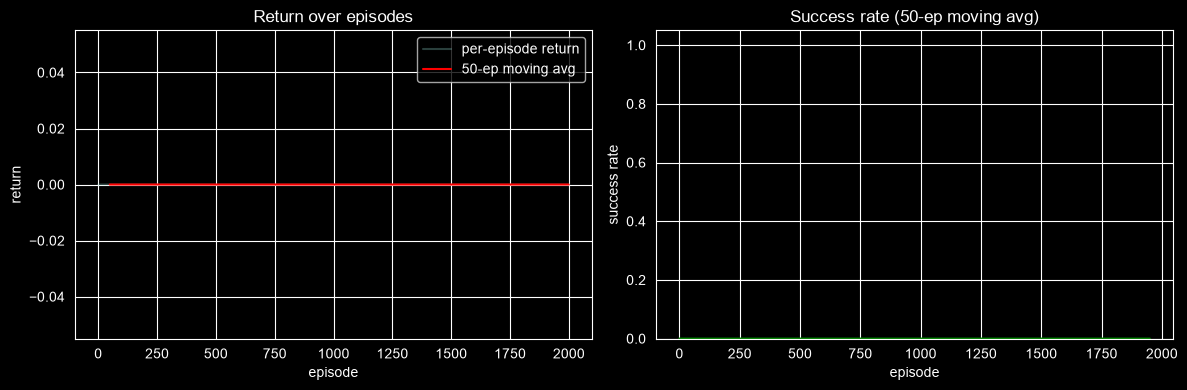

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML

# ========== 环境与智能体（假设已修好上面两个 bug） ==========
env = FrozenLakeEnv(map_name="4x4", is_slippery=False, render_mode="rgb_array")
state_nums = env.n_states
action_nums = env.n_actions

agent = Q_leaning(action_nums=action_nums, state_nums=state_nums, epslion=0.1, alpha=0.1, gamma=0.9)

# ========== 1. 训练 ==========
num_episodes = 2000
returns = []          # 每回合总回报
success = []          # 每回合是否成功到达目标

for episode in range(num_episodes):
    state, info = env.reset(seed=episode)   # 固定种子便于复现
    done = False
    episode_return = 0
    while not done:
        action = agent.act(state)
        next_state, reward, terminated, truncated, info = env.step(action)
        done = terminated or truncated
        agent.update(state, action, reward, next_state)
        state = next_state
        episode_return += reward
    returns.append(episode_return)
    success.append(1 if episode_return > 0 else 0)

# ========== 2. 收敛图 ==========
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# 左图：每回合回报的滑动平均
window = 50
smoothed = np.convolve(returns, np.ones(window)/window, mode="valid")
axes[0].plot(returns, alpha=0.3, label="per-episode return")
axes[0].plot(range(window-1, num_episodes), smoothed, color="red", label=f"{window}-ep moving avg")
axes[0].set_xlabel("episode")
axes[0].set_ylabel("return")
axes[0].set_title("Return over episodes")
axes[0].legend()

# 右图：成功率滑动平均
smoothed_success = np.convolve(success, np.ones(window)/window, mode="valid")
axes[1].plot(smoothed_success, color="green")
axes[1].set_xlabel("episode")
axes[1].set_ylabel("success rate")
axes[1].set_title(f"Success rate ({window}-ep moving avg)")
axes[1].set_ylim(0, 1.05)

plt.tight_layout()
plt.show()

# ========== 3. 动画回放（用训练好的 Q 表贪心走一遍） ==========
frames = []
state, info = env.reset(seed=123)
done = False
while not done:
    frames.append(env.render())                 # 每步存一帧 rgb 数组
    action = np.argmax(agent.Q_table[state])    # 纯贪心，不再探索
    state, reward, terminated, truncated, info = env.step(action)
    done = terminated or truncated
frames.append(env.render())                     # 补最后一帧

fig_anim = plt.figure(figsize=(4, 4))
plt.axis("off")
im = plt.imshow(frames[0])

def update_frame(i):
    im.set_array(frames[i])
    return [im]

ani = animation.FuncAnimation(fig_anim, update_frame, frames=len(frames), interval=400, blit=True)
plt.close(fig_anim)   # 防止 Jupyter 里重复显示静态图
HTML(ani.to_jshtml())  # 在 Jupyter 中内嵌播放动画